## Imports

Let's start by importing the necessary libraries.

In [81]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.base import BaseEstimator, ClusterMixin
from sklearn.datasets import make_blobs

## Generate Sample Data

We'll generate some sample data to test our implementation.

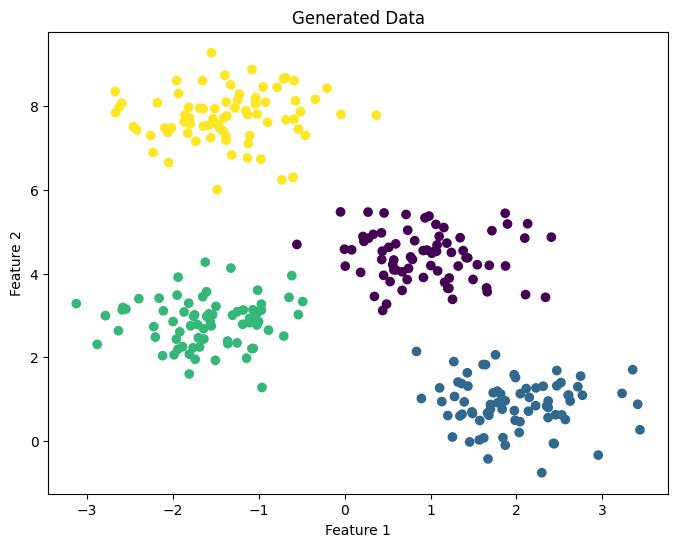

In [82]:
# Generate sample data
X, true_labels = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=true_labels)
plt.title('Generated Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

## Understanding $k$-means Algorithm


## 1. Random Initialization

The first step is to initialize the cluster centers. One common approach is to randomly select $k$ data points as the initial cluster centers.

**Your Task**: Implement the `random_initialize` function that selects $k$ random data points as initial cluster centers.

In [83]:
import random
def random_initialize(X, k, random_state=None):
    """
    Initialize k cluster centers randomly.
    
    Parameters:
    -----------
    X : array-like, shape (n_samples, n_features)
        The data to pick cluster centers from.
    k : int
        The number of cluster centers to initialize.
    random_state : int, default=None
        Determines random number generation for centroid initialization.
        
    Returns:
    --------
    centers : array, shape (k, n_features)
        The initial cluster centers.
    """
    if random_state is not None:
        np.random.seed(random_state)
    # YOUR CODE HERE [5 points]
    if k <= len(X):
        indices = np.random.choice(len(X), k, replace=False)
        return X[indices]

    else:
        print("Selected k greater than the number of data points")

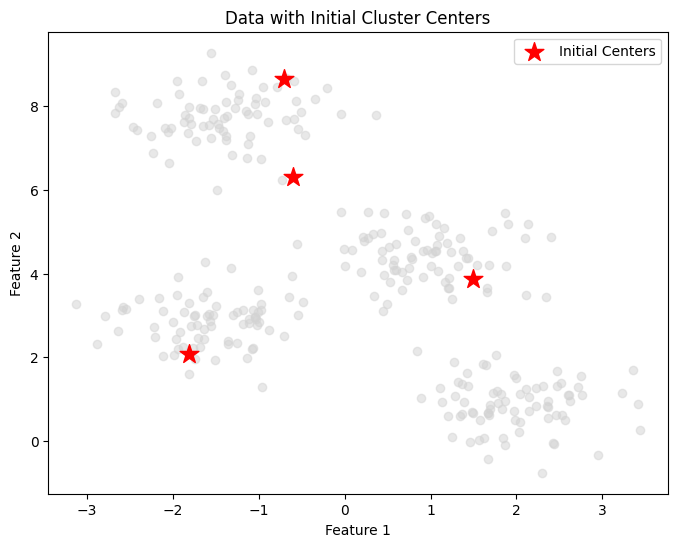

In [84]:
# Test the function
k = 4
initial_centers = random_initialize(X, k, random_state=42)

# Visualize the data and initial centers
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c='lightgray', alpha=0.5)
plt.scatter(initial_centers[:, 0], initial_centers[:, 1], c='red', s=200, marker='*', label='Initial Centers')
plt.title('Data with Initial Cluster Centers')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()

## 2. Assign Cluster Labels

The next step is to assign each data point to the nearest cluster center.

**Your Task**: Implement the `assign_cluster_labels` function that assigns each data point to the nearest cluster center.

In [86]:
def assign_cluster_labels(X, centers):
    """
    Assign each data point to the nearest cluster center.
    
    Parameters:
    -----------
    X : array-like, shape (n_samples, n_features)
        The data to assign labels to.
    centers : array-like, shape (k, n_features)
        The current cluster centers.
        
    Returns:
    --------
    labels : array, shape (n_samples,)
        The cluster labels for each data point.
    """
    labels = []
    # YOUR CODE HERE [5 points]
    # Hint: You can use np.linalg.norm to compute distances
    for i in X:
        distances = [np.linalg.norm(i-center) for center in centers]
        nearest_index = np.argmin(distances)
        labels.append(nearest_index)

    return np.array(labels)

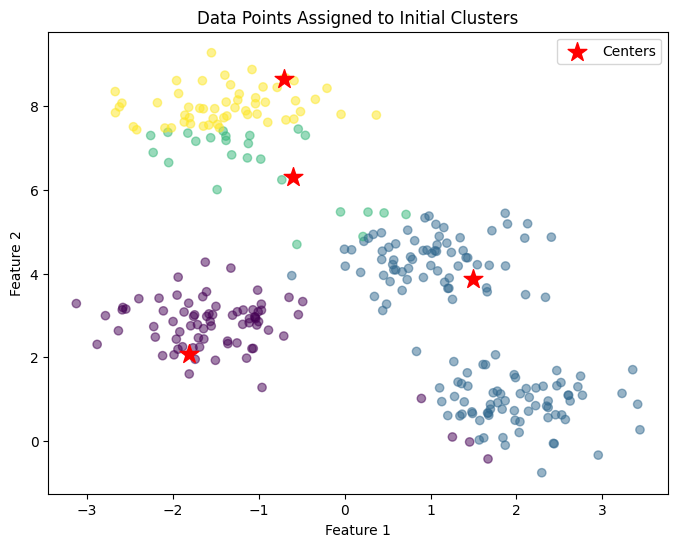

In [87]:
# Test the function
labels = assign_cluster_labels(X, initial_centers)

# Visualize the assignments
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', alpha=0.5)
plt.scatter(initial_centers[:, 0], initial_centers[:, 1], c='red', s=200, marker='*', label='Centers')
plt.title('Data Points Assigned to Initial Clusters')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()

## 3. Find New Cluster Centers

After assigning labels, we need to update the cluster centers by taking the mean of all points assigned to each cluster.

In [97]:
def find_cluster_centers(X, labels, k):
    """
    Compute new cluster centers as the mean of all points assigned to each cluster.
    
    Parameters:
    -----------
    X : array-like, shape (n_samples, n_features)
        The data points.
    labels : array-like, shape (n_samples,)
        The cluster label of each data point.
    k : int
        The number of clusters.
        
    Returns:
    --------
    centers : array, shape (k, n_features)
        The new cluster centers.
    """
    # YOUR CODE HERE [5 points]
    # Hint: Be careful with empty clusters!
    cluster = [X[labels == z] for z in range(k)]
    sum_array = []
    for i in range(k):
        if len(cluster[i]) > 0:
            sum_array.append(np.mean(cluster[i], axis=0, keepdims=True))
        else:
            random_point = X[np.random.choice(len(X), 1)]
            sum_array.append(random_point)

    return np.vstack(sum_array)



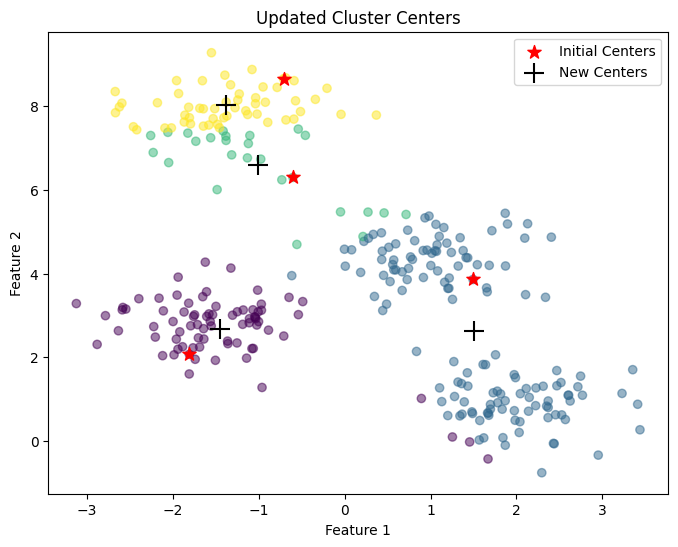

In [89]:
# Test the function
new_centers = find_cluster_centers(X, labels, k)

# Visualize the new centers
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', alpha=0.5)
plt.scatter(initial_centers[:, 0], initial_centers[:, 1], c='red', s=100, marker='*', label='Initial Centers')
plt.scatter(new_centers[:, 0], new_centers[:, 1], c='black', s=200, marker='+', label='New Centers')
plt.title('Updated Cluster Centers')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()

## 4. Check Convergence

Next, we need to check if the algorithm has converged, which occurs when the cluster assignments no longer change or when the change in cluster centers is below a certain threshold.

In [91]:
def assert_converged(old_centers, new_centers, tol=1e-4):
    """
    Check if the algorithm has converged.
    
    Parameters:
    -----------
    old_centers : array-like, shape (k, n_features)
        The previous cluster centers.
    new_centers : array-like, shape (k, n_features)
        The new cluster centers.
    tol : float, default=1e-4
        The tolerance to declare convergence.
        
    Returns:
    --------
    converged : bool
        True if the algorithm has converged, False otherwise.
    """
    # YOUR CODE HERE [5 points]
    # Hint: Compare the Euclidean distance between the old and new centers
    dist = np.linalg.norm(new_centers - old_centers)
    if dist < tol:
        return True
    else:
        return False


In [92]:
# Test the function
# Let's create slightly moved centers to test
slightly_moved_centers = new_centers.copy()
slightly_moved_centers += 1e-6  # Very small change
significantly_moved_centers = new_centers.copy()
significantly_moved_centers += 1e-2  # Larger change

print(f"Should be converged: {assert_converged(new_centers, slightly_moved_centers)}")
print(f"Should not be converged: {assert_converged(new_centers, significantly_moved_centers)}")

Should be converged: True
Should not be converged: False


Putting It All Together: The `MyKMeans` Class

In [93]:
class MyKMeans(BaseEstimator, ClusterMixin):
    """
    K-means clustering algorithm.
    
    Parameters:
    -----------
    n_clusters : int, default=8
        The number of clusters to form.
    max_iter : int, default=300
        Maximum number of iterations for a single run.
    tol : float, default=1e-4
        Tolerance to declare convergence.
    random_state : int, default=None
        Determines random number generation for centroid initialization.
    
    Attributes:
    -----------
    cluster_centers_ : array, shape (n_clusters, n_features)
        Coordinates of cluster centers.
    labels_ : array, shape (n_samples,)
        Labels of each point.
    inertia_ : float
        Sum of squared distances of samples to their closest cluster center.
    n_iter_ : int
        Number of iterations run.
    """
    
    def __init__(self, n_clusters=8, max_iter=300, tol=1e-4, random_state=None):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
    
    def fit(self, X):
        """
        Compute k-means clustering.
        
        Parameters:
        -----------
        X : array-like, shape (n_samples, n_features)
            Training instances to cluster.
            
        Returns:
        --------
        self : object
            Fitted estimator.
        """
        # Initialize the cluster centers
        self.cluster_centers_ = random_initialize(X, self.n_clusters, self.random_state)
        
        # Initialize variables for the iterative process
        self.n_iter_ = 0
        converged = False
        
        while not converged and self.n_iter_ < self.max_iter:
            # Assign labels based on current centers
            self.labels_ = assign_cluster_labels(X, self.cluster_centers_)
            
            # Calculate new centers
            new_centers = find_cluster_centers(X, self.labels_, self.n_clusters)
            
            # Check for convergence
            converged = assert_converged(self.cluster_centers_, new_centers, self.tol)
            
            # Update centers
            self.cluster_centers_ = new_centers
            
            # Increment iteration counter
            self.n_iter_ += 1
        
        # Calculate inertia (sum of squared distances to closest center)
        self.inertia_ = self._compute_inertia(X)
        
        return self
    
    def _compute_inertia(self, X):
        """Compute the sum of squared distances to the closest center."""
        distances = np.zeros(X.shape[0])
        
        for i, center in enumerate(self.cluster_centers_):
            mask = (self.labels_ == i)
            if np.any(mask):
                distances[mask] = np.sum((X[mask] - center) ** 2, axis=1)
        
        return np.sum(distances)
    
    def predict(self, X):
        """
        Predict the closest cluster each sample in X belongs to.
        
        Parameters:
        -----------
        X : array-like, shape (n_samples, n_features)
            New data to predict.
            
        Returns:
        --------
        labels : array, shape (n_samples,)
            Index of the cluster each sample belongs to.
        """
        return assign_cluster_labels(X, self.cluster_centers_)
    
    def fit_predict(self, X):
        """
        Compute cluster centers and predict cluster index for each sample.
        
        Parameters:
        -----------
        X : array-like, shape (n_samples, n_features)
            New data to predict.
            
        Returns:
        --------
        labels : array, shape (n_samples,)
            Index of the cluster each sample belongs to.
        """
        self.fit(X)
        return self.labels_

## Test the Complete $k$-means Implementation


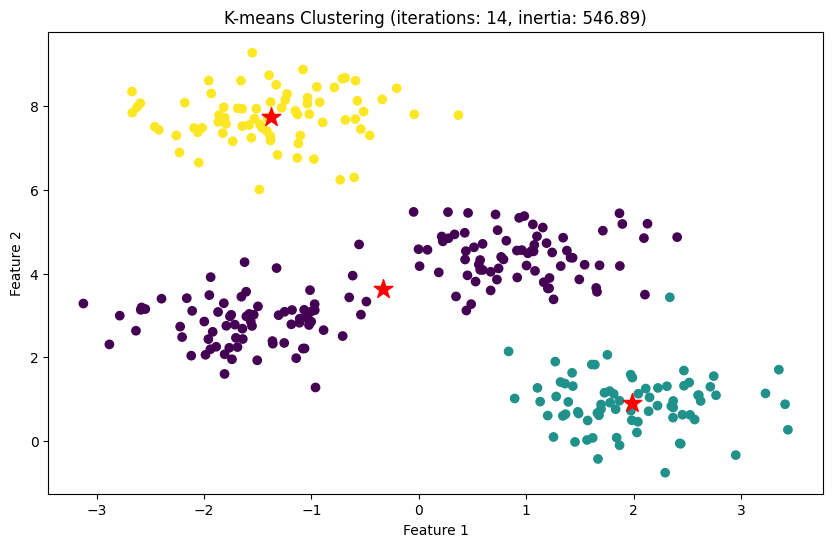

In [94]:
# Test the MyKMeans class
kmeans = MyKMeans(n_clusters=3, random_state=42)
kmeans.fit(X)

# Visualize the results
plt.figure(figsize=(10, 6))
plt.scatter(X[:, 0], X[:, 1], c=kmeans.labels_, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', s=200, marker='*')
plt.title(f'K-means Clustering (iterations: {kmeans.n_iter_}, inertia: {kmeans.inertia_:.2f})')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

# Applying on real data-set

In [ ]:
from sklearn.datasets import load_iris
iris = load_iris()
X = iris.data  # 4 features
y = iris.target 

In [125]:
kmeans = MyKMeans(n_clusters=3, random_state=42)
X_clustering = kmeans.fit(X)
predicted_labels = kmeans.labels_
predicted_labels.shape

(150,)

In [119]:
from sklearn.decomposition import PCA
import numpy as np

def apply_pca_2d(X, n_components=2):
    pca = PCA(n_components=n_components)
    X_reduced = pca.fit_transform(X)
    return X_reduced


In [120]:
X_reduced = apply_pca_2d(X, n_components=2)
print(X_reduced.shape)

(150, 2)


In [126]:
import matplotlib.pyplot as plt

def plot_pca_comparison(X_reduced, true_labels, predicted_labels):
    """
    Plot side-by-side PCA projection with true labels and clustering results.
    
    Parameters:
    -----------
    X_reduced : array-like, shape (n_samples, 2)
        The dataset reduced to 2D via PCA.
    true_labels : array-like, shape (n_samples,)
        The ground truth labels.
    predicted_labels : array-like, shape (n_samples,)
        The labels obtained from the clustering algorithm.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    
    # Plot 1: PCA Projection with True Labels
    ax1.scatter(X_reduced[:, 0], X_reduced[:, 1], c=true_labels, cmap='viridis', s=50)
    ax1.set_title("PCA Projection with True Labels")
    ax1.set_xlabel("PC1")
    ax1.set_ylabel("PC2")
    
    # Plot 2: PCA Projection with Predicted Clustering Labels
    ax2.scatter(X_reduced[:, 0], X_reduced[:, 1], c=predicted_labels, cmap='viridis', s=50)
    ax2.set_title("PCA Projection with Clustering Results")
    ax2.set_xlabel("PC1")
    ax2.set_ylabel("PC2")
    
    plt.show()


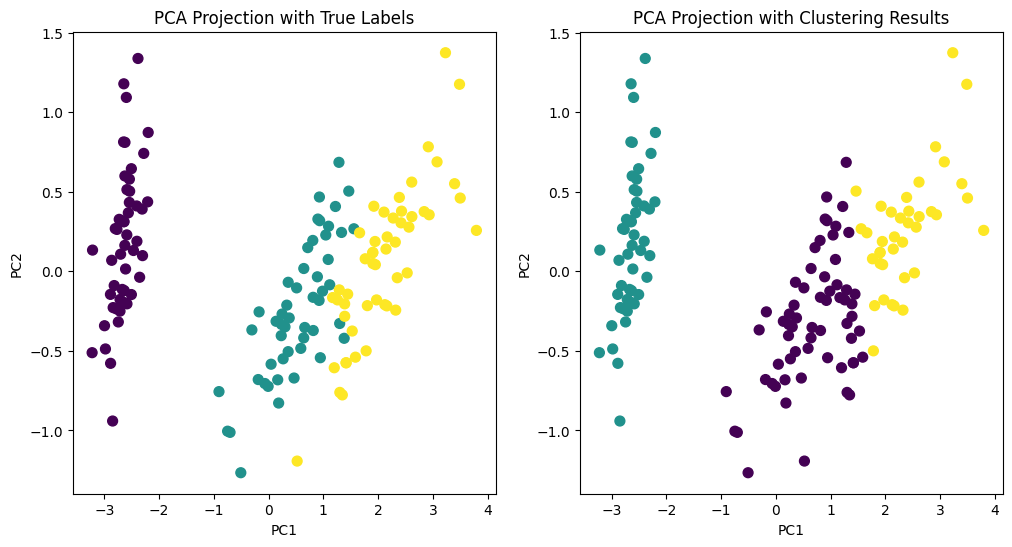

In [127]:
plot_pca_comparison(X_reduced, y, predicted_labels)